Plant Leaf Disease Detection Using Image Processing and Transfer Learning

## 1. Import Libraries

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Paths

In [13]:
PROJECT_ROOT = os.path.abspath("..")

TRAIN_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "train"
)

VALIDATION_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "validation"
)

TEST_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "test"
)

print("Training directory:")
print(TRAIN_DIR)

print("\nValidation directory:")
print(VALIDATION_DIR)

print("\nTesting directory:")
print(TEST_DIR)

Training directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\train

Validation directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\validation

Testing directory:
c:\PROJECTS\Plant-Disease-Detection-IPA-Model\data\processed\test


## 3. Dataset Information

In [14]:
classes = [
    "healthy",
    "early_blight",
    "late_blight",
    "leaf_mold"
]

for class_name in classes:

    folder = os.path.join(
        TRAIN_DIR,
        class_name
    )

    count = len([
        file for file in os.listdir(folder)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    print(f"{class_name:15s}: {count}")

healthy        : 400
early_blight   : 400
late_blight    : 400
leaf_mold      : 400


## 4. Sample Images

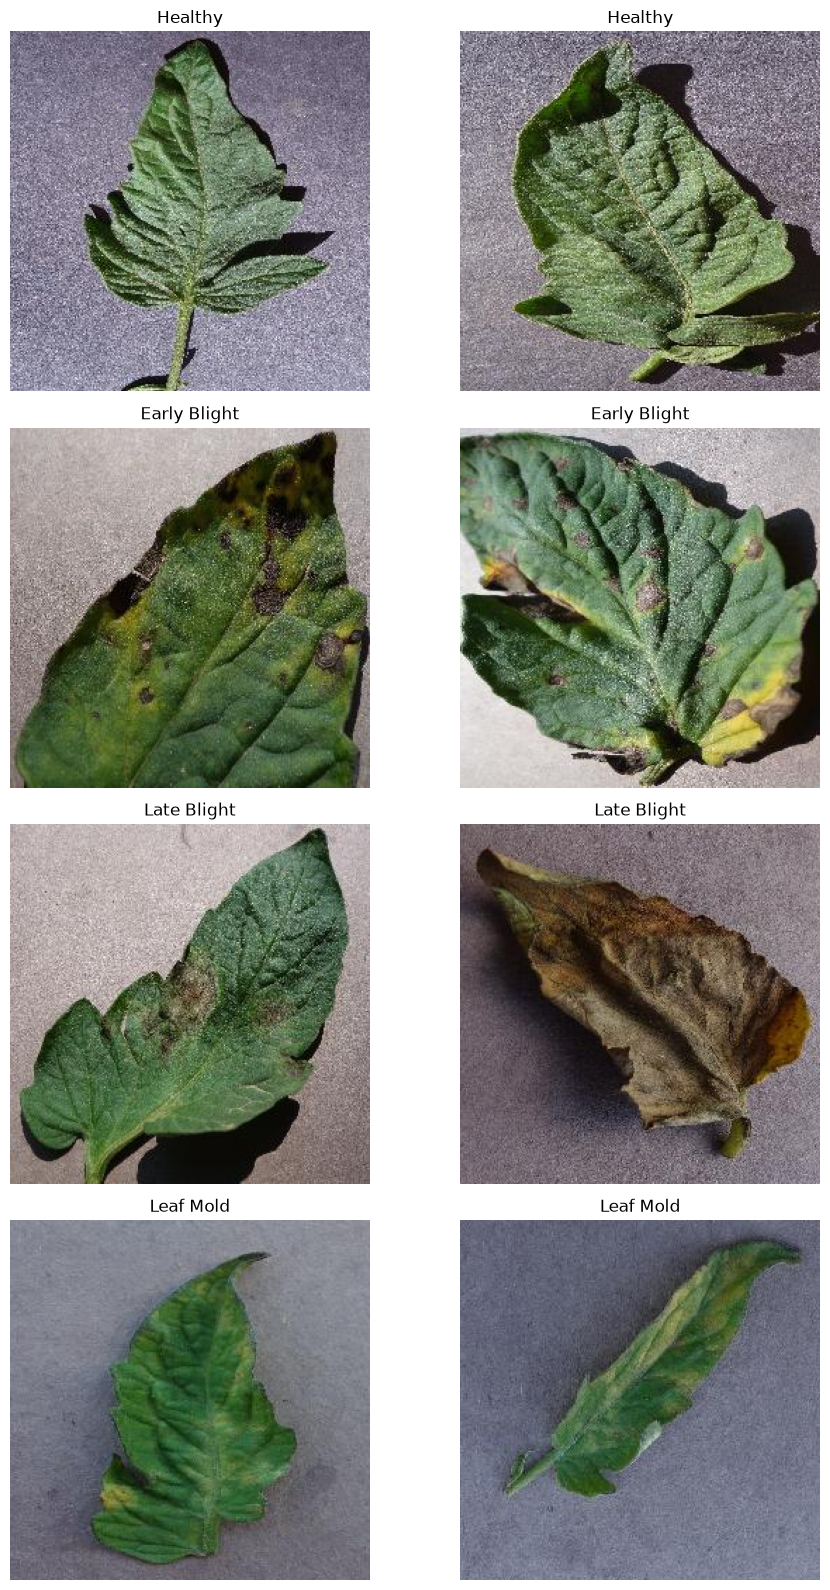

In [15]:
fig, axes = plt.subplots(
    4,
    2,
    figsize=(10, 16)
)

for row, class_name in enumerate(classes):

    folder = os.path.join(
        TRAIN_DIR,
        class_name
    )

    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    selected_images = images[:2]

    for col, image_file in enumerate(selected_images):

        image_path = os.path.join(
            folder,
            image_file
        )

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            class_name.replace("_", " ").title()
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


## 5. Dataset Analysis

In this section, we analyze the distribution of images across
the four tomato leaf categories in the training, validation,
and testing datasets.

In [16]:
import os
import pandas as pd

classes = [
    "healthy",
    "early_blight",
    "late_blight",
    "leaf_mold"
]

splits = ["train", "validation", "test"]

dataset_counts = {}

for split in splits:

    split_dir = os.path.join(PROJECT_ROOT, "data", "processed", split)

    dataset_counts[split] = {}

    for class_name in classes:

        class_dir = os.path.join(split_dir, class_name)

        image_files = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        dataset_counts[split][class_name] = len(image_files)


df_counts = pd.DataFrame(dataset_counts)

df_counts

,train,validation,test
healthy,400,50,50
early_blight,400,50,50
late_blight,400,50,50
leaf_mold,400,50,50


In [17]:
print("DATASET SUMMARY")
print("-" * 40)

for split in splits:

    total = sum(dataset_counts[split].values())

    print(f"{split.capitalize()} images: {total}")

total_images = sum(
    sum(dataset_counts[split].values())
    for split in splits
)

print("-" * 40)
print("Total images:", total_images)

DATASET SUMMARY
----------------------------------------
Train images: 1600
Validation images: 200
Test images: 200
----------------------------------------
Total images: 2000


## 5.1 Class Distribution Visualization

A bar chart is used to visualize the number of images
available in each category across the three dataset splits.

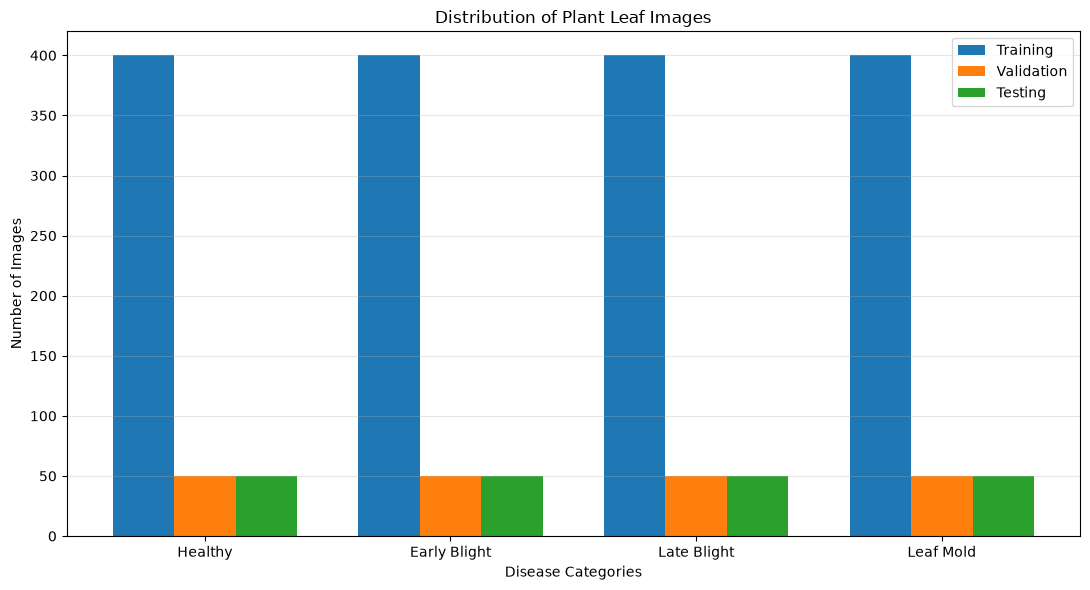

In [18]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    df_counts["train"],
    width,
    label="Training"
)

plt.bar(
    x,
    df_counts["validation"],
    width,
    label="Validation"
)

plt.bar(
    x + width,
    df_counts["test"],
    width,
    label="Testing"
)

plt.xlabel("Disease Categories")
plt.ylabel("Number of Images")

plt.title("Distribution of Plant Leaf Images")

plt.xticks(
    x,
    ["Healthy", "Early Blight", "Late Blight", "Leaf Mold"]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

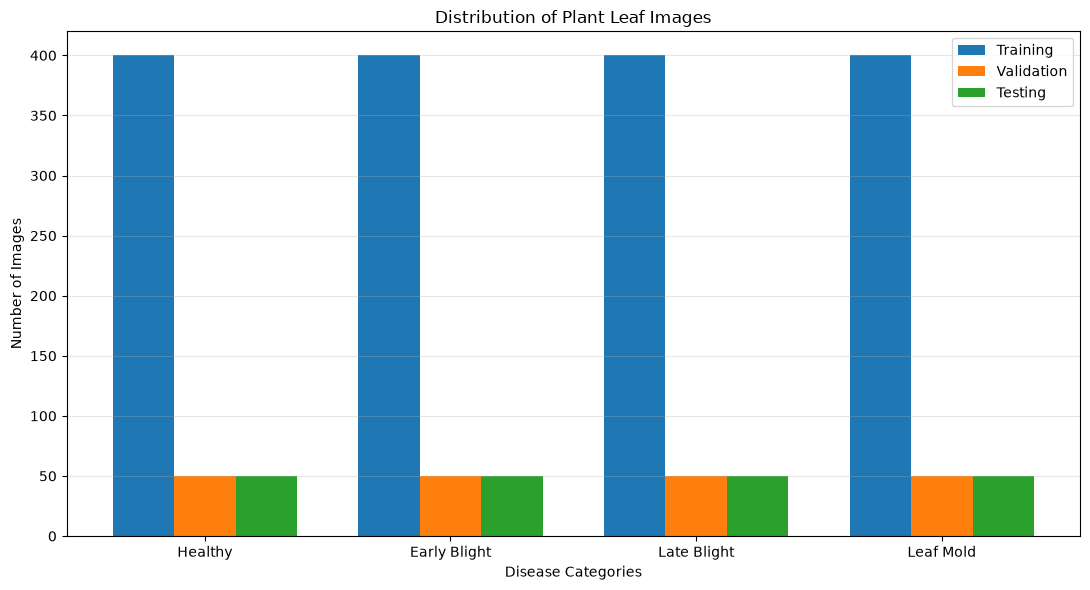

In [19]:
os.makedirs(
    os.path.join(PROJECT_ROOT, "results"),
    exist_ok=True
)

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    df_counts["train"],
    width,
    label="Training"
)

plt.bar(
    x,
    df_counts["validation"],
    width,
    label="Validation"
)

plt.bar(
    x + width,
    df_counts["test"],
    width,
    label="Testing"
)

plt.xlabel("Disease Categories")
plt.ylabel("Number of Images")
plt.title("Distribution of Plant Leaf Images")

plt.xticks(
    x,
    ["Healthy", "Early Blight", "Late Blight", "Leaf Mold"]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_ROOT, "results", "class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPU available: []


In [21]:
IMAGE_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

NUM_CLASSES = 4

In [22]:
train_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED

)

Found 1600 files belonging to 4 classes.


In [24]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(

    VALIDATION_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

Found 200 files belonging to 4 classes.


In [25]:
test_dataset = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

Found 200 files belonging to 4 classes.


In [26]:
class_names = train_dataset.class_names

print("Classes detected by TensorFlow:")

for i, name in enumerate(class_names):

    print(i, ":", name)

Classes detected by TensorFlow:
0 : early_blight
1 : healthy
2 : late_blight
3 : leaf_mold


In [27]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)

    print("Label batch shape:", labels.shape)

    print("Image data type:", images.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())

    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 251.58191


## 6. Resized Images

All input images are resized to 224 × 224 pixels
while retaining their RGB color channels.

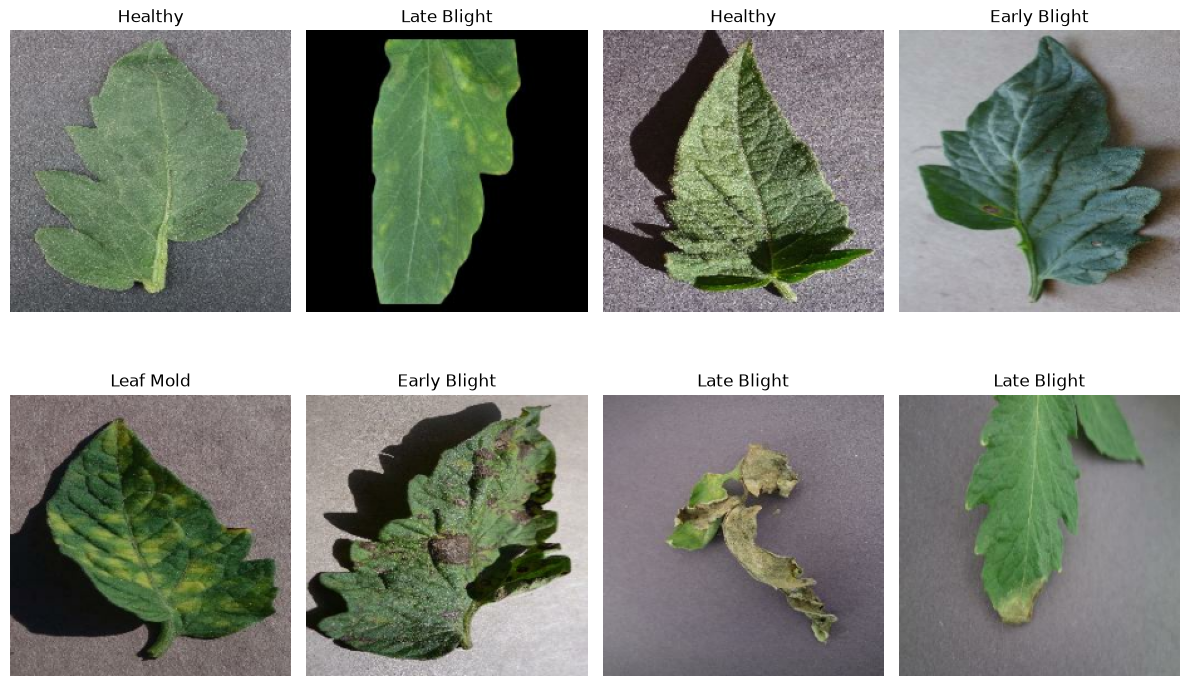

In [29]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(8):

        ax = plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = class_names[labels[i].numpy()]

        plt.title(label.replace("_", " ").title())

        plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Data Augmentation

Data augmentation is used to artificially introduce variations
in the training images. This helps improve the generalization
ability of the model and reduces overfitting.

In [30]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.10),

    tf.keras.layers.RandomZoom(0.10)

], name="data_augmentation")

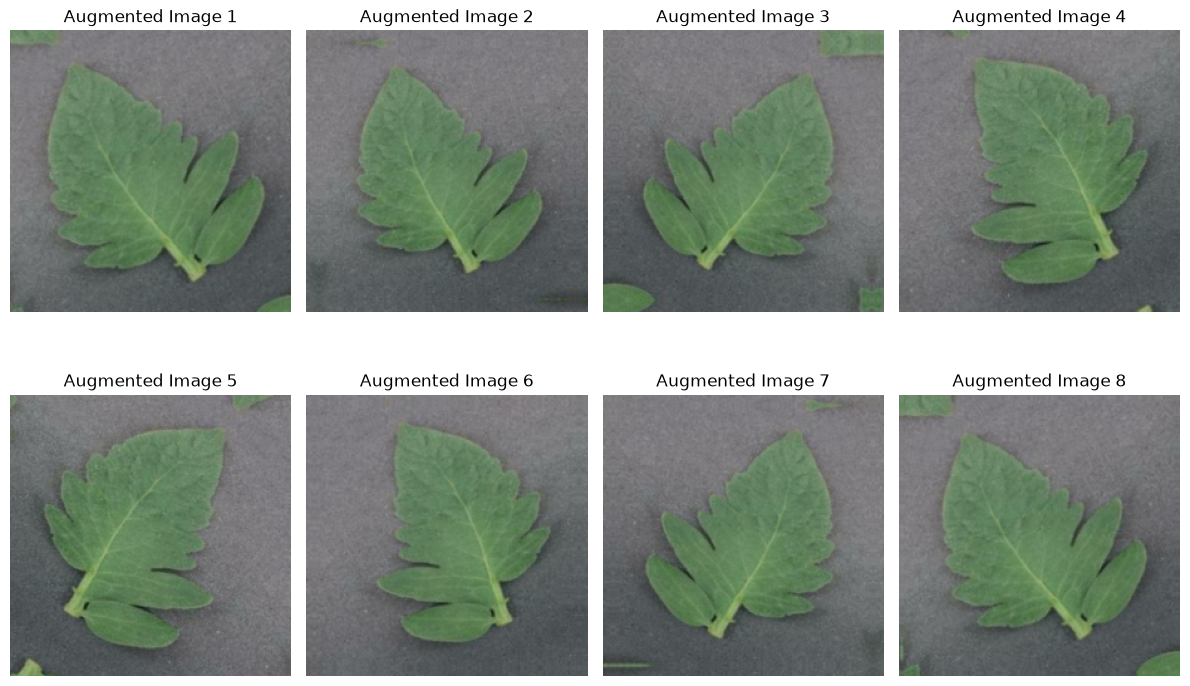

In [31]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    original_image = images[0]

    for i in range(8):

        augmented_image = data_augmentation(
            tf.expand_dims(original_image, 0),
            training=True
        )

        augmented_image = augmented_image[0]

        ax = plt.subplot(2, 4, i + 1)

        plt.imshow(
            tf.clip_by_value(
                augmented_image / 255.0,
                0,
                1
            )
        )

        plt.title(f"Augmented Image {i+1}")

        plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Dataset Performance Optimization

Prefetching is used to improve the efficiency of the
input pipeline by preparing subsequent batches while
the current batch is being processed.

In [32]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset optimization completed.")

Dataset optimization completed.


In [33]:
print("FINAL DATASET VERIFICATION")
print("=" * 45)

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

print("\nClass names:")

for i, name in enumerate(class_names):
    print(i, ":", name)

print("\nDataset batches:")

print(
    "Training batches:",
    tf.data.experimental.cardinality(train_dataset).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(validation_dataset).numpy()
)

print(
    "Testing batches:",
    tf.data.experimental.cardinality(test_dataset).numpy()
)

FINAL DATASET VERIFICATION
Image size: (224, 224)
Batch size: 32
Number of classes: 4

Class names:
0 : early_blight
1 : healthy
2 : late_blight
3 : leaf_mold

Dataset batches:
Training batches: 50
Validation batches: 7
Testing batches: 7
